## A prototype model for identifying key mutations for FIPV/FECV switch

### 1. Minimum implementation of GWAS-like statistical test

In [1]:
# Arial fontがないためこちらで実行
import pandas as pd
import numpy as np
from Bio import SeqIO
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.font_manager import FontProperties, findfont

# 1. SVGのフォント設定（テキストとして保持する設定）
mpl.rcParams['svg.fonttype'] = 'none'

# 2. Arialフォントをシステムから検索して設定
try:
    # Arialを探し、パスを取得
    arial_path = findfont(FontProperties(family='Arial'))
    # FontPropertiesを生成
    arial_font = FontProperties(fname=arial_path)
    # matplotlibに適用
    plt.rcParams['font.family'] = arial_font.get_name()
    print(f"Arialフォントを適用しました: {arial_path}")
except Exception as e:
    print(f"Arialが見つかりません。デフォルトフォントを使用します: {e}")
    plt.rcParams['font.family'] = 'sans-serif'

Arialフォントを適用しました: /System/Library/Fonts/Supplemental/Arial.ttf


In [2]:
meta = pd.read_csv("FCoV1_S_all_seq_final_meta_20260306.tsv", sep="\t")
meta

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,4398,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,4404,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI
...,...,...,...,...,...,...,...,...,...,...,...,...,...
443,JQ304330.1,FECV,Feline coronavirus,FECV141,taxon:12663,348,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI
444,FJ917532.1,FIPV,Feline coronavirus,FIPV-UCD11b-1a,taxon:12663,186,NaN,USA,Felis catus (cat),diseased lesional tissue,31-Mar-2008,24-JUL-2016,NCBI
445,PP097359.1,FIPV,Feline coronavirus,FIPV/UGM/BUDF,taxon:12663,360,NaN,Indonesia,Felis catus,ascites,NaN,04-FEB-2024,NCBI
446,JQ304361.1,FECV,Feline coronavirus,FECV378,taxon:12663,543,NaN,Netherlands,Felis catus,feces,NaN,12-JUL-2012,NCBI


In [3]:
# FCS partial seqs were manually obtained from Aliview
# load protien alignment
ids = []
seqs = []

for rec in SeqIO.parse("FCS_all_aa.fas", "fasta"):
    ids.append(rec.id)
    seqs.append(str(rec.seq))

df_fasta = pd.DataFrame({"ID": ids, "Seq": seqs})
df_fasta

,ID,Seq
0,PQ416775.1,AQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SV...
1,PX315748.1,AQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TV...
2,PX315749.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...
3,PX315750.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...
4,PX315751.1,TQAAVINDEIVGAITAINQTDLFEFVNHTESRRSRMSAPS----TV...
...,...,...
161,HF954968.1,---AVINDEIVGAITAVNQTDLFEFVNHTHLRRSHRSTSE----SV...
162,FJ917534.1,AQAAVINDEIVGVITAVNQTDLFAFVNHTSARKSRRSVTE----SV...
163,HF954950.1,AQAAVINDEIVGVITAVNQTDLFEFVNHTHSKRSRRSTSN----LV...
164,HF954933.1,---AVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSASN----SV...


In [4]:
df_fasta['X_count'] = df_fasta['Seq'].str.count('X')
df_fasta

,ID,Seq,X_count
0,PQ416775.1,AQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SV...,0
1,PX315748.1,AQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TV...,0
2,PX315749.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...,0
3,PX315750.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...,0
4,PX315751.1,TQAAVINDEIVGAITAINQTDLFEFVNHTESRRSRMSAPS----TV...,0
...,...,...,...
161,HF954968.1,---AVINDEIVGAITAVNQTDLFEFVNHTHLRRSHRSTSE----SV...,0
162,FJ917534.1,AQAAVINDEIVGVITAVNQTDLFAFVNHTSARKSRRSVTE----SV...,0
163,HF954950.1,AQAAVINDEIVGVITAVNQTDLFEFVNHTHSKRSRRSTSN----LV...,0
164,HF954933.1,---AVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSASN----SV...,0


In [5]:
df_merged = pd.merge(meta, df_fasta, how="inner", left_on="Accession", right_on="ID")
df_merged

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,AQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SV...,0
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,AQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TV...,0
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...,0
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,4398,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,PX315750.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...,0
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,4404,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,PX315751.1,TQAAVINDEIVGAITAINQTDLFEFVNHTESRRSRMSAPS----TV...,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161,HF954968.1,FIPV,Feline coronavirus,FIPV D04 93-1,taxon:12663,147,NaN,USA:PA,Felis catus,kidney of a diseased cat,2004,03-JUL-2013,NCBI,HF954968.1,---AVINDEIVGAITAVNQTDLFEFVNHTHLRRSHRSTSE----SV...,0
162,FJ917534.1,FIPV,Feline coronavirus,FIPV-UCD11b-2a,taxon:12663,4413,NaN,USA,Felis catus (cat),diseased lesional tissue,04-Apr-2008,24-JUL-2016,NCBI,FJ917534.1,AQAAVINDEIVGVITAVNQTDLFAFVNHTSARKSRRSVTE----SV...,0
163,HF954950.1,FECV,Feline coronavirus,FECV 167,taxon:12663,156,NaN,USA:RI,Felis catus,feces of a healthy cat,2010,03-JUL-2013,NCBI,HF954950.1,AQAAVINDEIVGVITAVNQTDLFEFVNHTHSKRSRRSTSN----LV...,0
164,HF954933.1,FECV,Feline coronavirus,FECV 131,taxon:12663,148,NaN,USA:WI,Felis catus,feces of a healthy cat,2010,03-JUL-2013,NCBI,HF954933.1,---AVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSASN----SV...,0


In [6]:
df_merged_filtered = df_merged[df_merged['X_count'] < 100]
# replace 'FECV' in 'FECV_or_FIPV' with '0' and 'FIPV' with '1' and 'unknown' with '' for better encoding
df_merged_filtered['FECV_or_FIPV_encodes'] = df_merged_filtered['biotype'].replace({'FECV': '0', 'FIPV': '1', 'unknown': ''})
df_merged_filtered

,Accession,biotype,Organism_Name,Isolate,Species,Spike_Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count,FECV_or_FIPV_encodes
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,4407,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,AQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SV...,0,1
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,3699,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,AQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TV...,0,1
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,3729,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...,0,1
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,4398,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,PX315750.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...,0,1
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,4404,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,PX315751.1,TQAAVINDEIVGAITAINQTDLFEFVNHTESRRSRMSAPS----TV...,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
161,HF954968.1,FIPV,Feline coronavirus,FIPV D04 93-1,taxon:12663,147,NaN,USA:PA,Felis catus,kidney of a diseased cat,2004,03-JUL-2013,NCBI,HF954968.1,---AVINDEIVGAITAVNQTDLFEFVNHTHLRRSHRSTSE----SV...,0,1
162,FJ917534.1,FIPV,Feline coronavirus,FIPV-UCD11b-2a,taxon:12663,4413,NaN,USA,Felis catus (cat),diseased lesional tissue,04-Apr-2008,24-JUL-2016,NCBI,FJ917534.1,AQAAVINDEIVGVITAVNQTDLFAFVNHTSARKSRRSVTE----SV...,0,1
163,HF954950.1,FECV,Feline coronavirus,FECV 167,taxon:12663,156,NaN,USA:RI,Felis catus,feces of a healthy cat,2010,03-JUL-2013,NCBI,HF954950.1,AQAAVINDEIVGVITAVNQTDLFEFVNHTHSKRSRRSTSN----LV...,0,0
164,HF954933.1,FECV,Feline coronavirus,FECV 131,taxon:12663,148,NaN,USA:WI,Felis catus,feces of a healthy cat,2010,03-JUL-2013,NCBI,HF954933.1,---AVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSASN----SV...,0,0


In [7]:
df_selected = df_merged_filtered[['Accession', 'Seq', 'FECV_or_FIPV_encodes']]
df_selected = df_selected[df_selected['FECV_or_FIPV_encodes'] != '']
df_selected.rename(columns={'FECV_or_FIPV_encodes': 'FIP_label'}, inplace=True)
df_selected.reset_index(drop=True, inplace=True)
df_selected

,Accession,Seq,FIP_label
0,PQ416775.1,AQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTSE----SV...,1
1,PX315748.1,AQVAVINDEIVGAITAINQTDLFEFVNHTQSRSSRRSTPE----TV...,1
2,PX315749.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...,1
3,PX315750.1,AQAAVINDEIVGVITSVNQTDLFEFVNHTQPRRARKSIFP----TV...,1
4,PX315751.1,TQAAVINDEIVGAITAINQTDLFEFVNHTESRRSRMSAPS----TV...,1
...,...,...,...
161,HF954968.1,---AVINDEIVGAITAVNQTDLFEFVNHTHLRRSHRSTSE----SV...,1
162,FJ917534.1,AQAAVINDEIVGVITAVNQTDLFAFVNHTSARKSRRSVTE----SV...,1
163,HF954950.1,AQAAVINDEIVGVITAVNQTDLFEFVNHTHSKRSRRSTSN----LV...,0
164,HF954933.1,---AVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSASN----SV...,0


### FECVをconsensusにした上でアミノ酸の性質変化を考慮
consensusの取得はfull_lengthのdatasetで実施済み。

In [8]:
# FECV consensusの作成
from collections import Counter

# 1. FECVのみ抽出
fecv_df = df_merged_filtered[df_merged_filtered['biotype'] == 'FECV'].copy()

# 2. seqをリスト形式に展開して各ポジションを列にする
# 注意: seqが文字列の場合、リストに変換してDataFrame化します
seq_matrix = pd.DataFrame([list(s) for s in fecv_df['Seq']])

# 3. コンセンサス配列の決定 (各列で最も頻度が高い文字)
consensus = seq_matrix.mode().iloc[0]

# 4. 多型サイトの特定 (ユニークなアミノ酸が2種類以上ある列)
polymorphic_sites = []
for col in seq_matrix.columns:
    counts = seq_matrix[col].value_counts()
    if len(counts) > 1:
        # ポジション（0-indexed）、アミノ酸の種類とカウントを記録
        polymorphic_sites.append({
            'position': col + 1, # 1-based indexにする場合
            'variation': dict(counts)
        })

poly_table = pd.DataFrame(polymorphic_sites)

In [9]:
# コンセンサス配列をリストに変換
consensus_list = consensus.tolist()
# 「一つの長い文字列」にしたい場合
consensus_str = "".join(consensus_list)
print(consensus_str)

AQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTP-----TVTTYTMPQFYY


In [10]:
# 多型テーブルの表示
print("--- 多型サイト一覧 ---")
print(poly_table.head(10))

len(poly_table['position'])

--- 多型サイト一覧 ---
   position                          variation
0         1                  {'A': 66, '-': 6}
1         2                  {'Q': 67, '-': 5}
2         3                  {'A': 67, '-': 5}
3         6                  {'I': 71, 'V': 1}
4        13                  {'A': 63, 'V': 9}
5        15                  {'T': 71, 'N': 1}
6        16                  {'A': 66, 'S': 6}
7        17         {'V': 57, 'I': 14, 'T': 1}
8        24  {'E': 64, 'G': 5, 'A': 2, 'V': 1}
9        26          {'V': 70, 'L': 1, 'I': 1}


34

In [11]:
# 多型の閾値設定 (例: 2種類以上、3種類以上など)
threshold = 4  # ここを 3 に変えれば「3種類以上の多型」を抽出します

polymorphic_sites = []
for col in seq_matrix.columns:
    counts = seq_matrix[col].value_counts()
    
    # 閾値でフィルタリング
    if len(counts) >= threshold:
        polymorphic_sites.append({
            'position': col + 1,
            'variation': dict(counts),
            'unique_types': len(counts) # 何種類あるか記録しておくと便利です
        })

poly_table = pd.DataFrame(polymorphic_sites)
print("--- 多型サイト一覧 ---")
print(poly_table.head(10))
len(poly_table['position'])

--- 多型サイト一覧 ---
   position                                          variation  unique_types
0        24                  {'E': 64, 'G': 5, 'A': 2, 'V': 1}             4
1        28         {'H': 52, 'N': 10, 'Q': 7, 'D': 2, 'R': 1}             5
2        30        {'Q': 35, 'H': 20, 'S': 12, 'R': 3, 'E': 2}             5
3        31  {'S': 52, 'T': 6, 'P': 5, 'A': 4, 'G': 2, 'V':...             8
4        32         {'R': 57, 'K': 11, 'Q': 2, 'H': 1, 'G': 1}             5
5        34                 {'S': 57, 'A': 13, 'L': 1, 'V': 1}             4
6        38  {'T': 47, 'A': 14, 'V': 3, 'E': 2, 'I': 1, 'P'...            10
7        39  {'P': 26, 'S': 23, 'E': 6, 'A': 4, 'L': 3, 'G'...            11
8        40  {'-': 15, 'V': 12, 'S': 9, 'E': 9, 'D': 6, 'N'...            12
9        41                  {'-': 63, 'S': 4, 'L': 3, 'T': 2}             4


15

In [12]:
# input
seqs = df_selected["Seq"].tolist()
y = df_selected["FIP_label"].to_numpy(dtype=int)

# 多数決で決定したコンセンサス(多型は考慮せず)
fecv_consensus = "AQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTPV----TVQTYTMPQFYY"

L = len(seqs[0])
OFFSET = 779  # 修正したオフセット値

AA_CLASS = {
    # hydrophobic / aliphatic
    "A": "hydrophobic",
    "V": "hydrophobic",
    "L": "hydrophobic",
    "I": "hydrophobic",
    "M": "hydrophobic",

    # aromatic
    "F": "aromatic",
    "Y": "aromatic",
    "W": "aromatic",

    # polar uncharged
    "S": "polar",
    "T": "polar",
    "N": "polar",
    "Q": "polar",

    # positively charged
    "K": "positive",
    "R": "positive",
    "H": "positive",

    # negatively charged
    "D": "negative",
    "E": "negative",

    # special cases
    "G": "special",
    "P": "special",
    "C": "special",

    # deletion
    #"-": "deletion",
}

INVALID_AA = set(["-", "X", "*", "?", "N"])  


def aa_class(aa):
    if aa in INVALID_AA:
        return None
    return AA_CLASS.get(aa, "other")


def fisher_from_mask(mask, y):
    a = int(np.sum(mask & (y == 1)))
    b = int(np.sum(mask & (y == 0)))
    c = int(np.sum((~mask) & (y == 1)))
    d = int(np.sum((~mask) & (y == 0)))

    OR = (a * d + 1e-9) / (b * c + 1e-9)
    _, p = fisher_exact([[a, b], [c, d]], alternative="two-sided")
    return a, b, c, d, OR, p

records = []

for pos in range(L):
    col = np.array([s[pos] for s in seqs])
    ref = fecv_consensus[pos]

    valid_mask = np.array([(aa not in INVALID_AA) and (ref not in INVALID_AA) for aa in col])

    if ref in INVALID_AA:
        continue

    col_valid = col[valid_mask]
    y_valid = y[valid_mask]

    if len(col_valid) < 3:
        continue

    uniq = np.unique(col_valid)

    # 1) exact mutation test
    for aa in uniq:
        if aa == ref:
            continue
        aa_mask = (col_valid == aa)
        a, b, c, d, OR, p = fisher_from_mask(aa_mask, y_valid)
        records.append({
            "test_type": "exact_aa",
            "feature": f"{ref}{pos + OFFSET}{aa}",
            "mutation": f"{ref}{pos + OFFSET}{aa}",
            "pos": pos + OFFSET,
            "ref": ref,
            "aa": aa,
            "ref_class": aa_class(ref),
            "aa_class": aa_class(aa),
            "a_case": a, "b_ctrl": b, "c_case_not": c, "d_ctrl_not": d,
            "OR": OR, "p": p, "n_valid": len(col_valid),
        })

    # 2) any mutation
    any_mut_mask = (col_valid != ref)
    if np.any(any_mut_mask) and np.any(~any_mut_mask):
        a, b, c, d, OR, p = fisher_from_mask(any_mut_mask, y_valid)
        records.append({
            "test_type": "any_mutation",
            "feature": f"{ref}{pos + OFFSET}mut",
            "mutation": f"{ref}{pos + OFFSET}mut",
            "pos": pos + OFFSET,
            "ref": ref,
            "aa": None,
            "ref_class": aa_class(ref),
            "aa_class": None,
            "a_case": a, "b_ctrl": b, "c_case_not": c, "d_ctrl_not": d,
            "OR": OR, "p": p, "n_valid": len(col_valid),
        })

    # 3) class changed
    ref_cls = aa_class(ref)
    col_cls = np.array([aa_class(aa) for aa in col_valid], dtype=object)
    cls_valid_mask = np.array([c is not None for c in col_cls])
    col_valid2 = col_valid[cls_valid_mask]
    col_cls2 = col_cls[cls_valid_mask]
    y_valid2 = y_valid[cls_valid_mask]

    if len(col_valid2) >= 3 and ref_cls is not None:
        class_changed_mask = (col_cls2 != ref_cls)
        if np.any(class_changed_mask) and np.any(~class_changed_mask):
            a, b, c, d, OR, p = fisher_from_mask(class_changed_mask, y_valid2)
            records.append({
                "test_type": "class_changed",
                "feature": f"{ref}{pos + OFFSET}class_change",
                "mutation": f"{ref}{pos + OFFSET}class_change",
                "pos": pos + OFFSET,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": "different_from_ref_class",
                "a_case": a, "b_ctrl": b, "c_case_not": c, "d_ctrl_not": d,
                "OR": OR, "p": p, "n_valid": len(col_valid2),
            })

    # 4) target class specific tests
    observed_classes = sorted(set([c for c in col_cls if c is not None]))
    for target_cls in observed_classes:
        if target_cls == ref_cls:
            continue
        target_class_mask = (col_cls2 == target_cls)
        if np.any(target_class_mask) and np.any(~target_class_mask):
            a, b, c, d, OR, p = fisher_from_mask(target_class_mask, y_valid2)
            records.append({
                "test_type": "target_class",
                "feature": f"{ref}{pos + OFFSET}{target_cls}",
                "mutation": f"{ref}{pos + OFFSET}{target_cls}",
                "pos": pos + OFFSET,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": target_cls,
                "a_case": a, "b_ctrl": b, "c_case_not": c, "d_ctrl_not": d,
                "OR": OR, "p": p, "n_valid": len(col_valid2),
            })

# =========================
# result table
# =========================
res = pd.DataFrame(records)

res["p_corrected_global"] = multipletests(res["p"], method="fdr_bh")[1]

res["p_corrected_by_type"] = np.nan
for t, idx in res.groupby("test_type").groups.items():
    res.loc[idx, "p_corrected_by_type"] = multipletests(res.loc[idx, "p"], method="fdr_bh")[1]

# =========================
# site summary
# =========================
site_summary = (
    res.groupby(["pos", "test_type"])
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

site_summary_overall = (
    res.groupby("pos")
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

In [13]:
site_summary

,pos,test_type,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,814,any_mutation,1.190774e-08,1.430611e-09,28.583451,1
1,814,class_changed,4.717202e-07,9.667763e-08,28.401129,1
2,811,any_mutation,2.057102e-04,3.707144e-05,3.247449,1
3,818,any_mutation,6.357574e-03,1.018410e-03,27.159416,1
4,811,class_changed,8.665841e-03,2.220047e-03,27.707982,1
...,...,...,...,...,...,...
121,823,class_changed,1.000000e+00,1.000000e+00,0.182322,1
122,802,class_changed,1.000000e+00,1.000000e+00,0.157629,1
123,827,any_mutation,1.000000e+00,1.000000e+00,0.143101,1
124,808,class_changed,1.000000e+00,1.000000e+00,0.128567,1


In [16]:
site_summary_overall

,pos,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,814,1.190774e-08,1.430611e-09,28.583451,13
1,811,2.057102e-04,3.707144e-05,27.707982,10
2,818,6.357574e-03,1.018410e-03,27.159416,19
3,809,1.964591e-02,4.130501e-03,20.717961,12
4,791,3.342459e-02,7.228215e-03,25.693079,5
5,813,6.689770e-02,1.473483e-02,27.397827,9
6,826,1.002127e-01,2.541787e-02,27.197157,6
7,781,1.907432e-01,7.384092e-02,26.873869,3
8,779,1.907432e-01,7.384092e-02,26.858831,5
9,815,2.171832e-01,8.349659e-02,26.791691,10


In [17]:
# 1. P値が 0.05 未満のポジションを特定
significant_pos = site_summary[site_summary["min_p_corrected_by_type"] < 0.05]["pos"]

# 2. そのポジションの詳細（検定タイプ含む）を site_summary から抽出
detailed_table = site_summary[site_summary["pos"].isin(significant_pos)].copy()

# 3. 見やすくするために並び替え（P値の小さい順）
detailed_table = detailed_table.sort_values("min_p_corrected_by_type")

# 表示
print(detailed_table[["pos", "test_type", "min_p_corrected_by_type", "max_abs_logOR", "n_features"]])
len(detailed_table["pos"])

    pos      test_type  min_p_corrected_by_type  max_abs_logOR  n_features
0   814   any_mutation             1.430611e-09      28.583451           1
1   814  class_changed             9.667763e-08      28.401129           1
2   811   any_mutation             3.707144e-05       3.247449           1
3   818   any_mutation             1.018410e-03      27.159416           1
4   811  class_changed             2.220047e-03      27.707982           1
5   818  class_changed             2.810334e-03       1.995358           1
6   809   any_mutation             4.130501e-03       1.169086           1
8   791   any_mutation             7.228215e-03       1.331544           1
9   809  class_changed             1.056054e-02       1.164666           1
10  813   any_mutation             1.473483e-02      27.397827           1
14  826   any_mutation             2.541787e-02      27.197157           1
7   814   target_class             4.377503e-02      27.564881           4
20  826  class_changed   

28

In [18]:
# ピボットテーブル化: 行=pos, 列=test_type, 値=P値
pivot_table = detailed_table.pivot(index="pos", columns="test_type", values="min_p_corrected_by_type")

# 結果を表示
print(pivot_table.head(10))

test_type  any_mutation  class_changed  exact_aa  target_class
pos                                                           
791        7.228215e-03   9.573829e-01  0.331121      0.876228
809        4.130501e-03   1.056054e-02  0.331121      0.193062
811        3.707144e-05   2.220047e-03  0.331121      0.134089
813        1.473483e-02   9.334948e-02  0.689794      0.733240
814        1.430611e-09   9.667763e-08  0.331121      0.043775
818        1.018410e-03   2.810334e-03  0.331121      0.134089
826        2.541787e-02   9.334948e-02  0.496961      0.193062


In [19]:
# mutationの性質(test_type)のカラムでp<0.05 をハイライト
# 背景色を塗る関数を定義
def highlight_low_p(val):
    color = 'yellow' if val < 0.05 else ''
    return f'background-color: {color}'

# スタイルを適用して表示
# .format("{:.10f}") で小数点表記、.applymap でハイライトを適用
styled_table = pivot_table.head(10).style \
    .format("{:.10f}") \
    .applymap(highlight_low_p)

styled_table

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_34500/1010008509.py:11: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(highlight_low_p)


test_type,any_mutation,class_changed,exact_aa,target_class
pos,,,,
791,0.0072282151,0.9573828929,0.3311205454,0.8762279420
809,0.0041305014,0.0105605449,0.3311205454,0.1930616196
811,0.0000370714,0.0022200475,0.3311205454,0.1340891152
813,0.0147348282,0.0933494799,0.6897944288,0.7332404383
814,0.0000000014,0.0000000967,0.3311205454,0.0437750265
818,0.0010184100,0.0028103342,0.3311205454,0.1340891152
826,0.0254178748,0.0933494799,0.4969614421,0.1930616196


ORの方向性(+-)を維持するスクリプト

In [14]:
# input
seqs = df_selected["Seq"].tolist()
y = df_selected["FIP_label"].to_numpy(dtype=int)

# 多数決で決定したコンセンサス(多型は考慮せず)
fecv_consensus = "AQAAVINDEIVGAITAVNQTDLFEFVNHTQSRRSRRSTPV----TVQTYTMPQFYY"

L = len(seqs[0])
OFFSET = 779  # 修正したオフセット値

AA_CLASS = {
    # hydrophobic / aliphatic
    "A": "hydrophobic",
    "V": "hydrophobic",
    "L": "hydrophobic",
    "I": "hydrophobic",
    "M": "hydrophobic",

    # aromatic
    "F": "aromatic",
    "Y": "aromatic",
    "W": "aromatic",

    # polar uncharged
    "S": "polar",
    "T": "polar",
    "N": "polar",
    "Q": "polar",

    # positively charged
    "K": "positive",
    "R": "positive",
    "H": "positive",

    # negatively charged
    "D": "negative",
    "E": "negative",

    # special cases
    "G": "special",
    "P": "special",
    "C": "special",

    # deletion
    #"-": "deletion",
}

INVALID_AA = set(["-", "X", "*", "?", "N"])  


def aa_class(aa):
    if aa in INVALID_AA:
        return None
    return AA_CLASS.get(aa, "other")


def fisher_from_mask(mask, y):
    a = int(np.sum(mask & (y == 1)))
    b = int(np.sum(mask & (y == 0)))
    c = int(np.sum((~mask) & (y == 1)))
    d = int(np.sum((~mask) & (y == 0)))

    OR = (a * d + 1e-9) / (b * c + 1e-9)
    _, p = fisher_exact([[a, b], [c, d]], alternative="two-sided")
    return a, b, c, d, OR, p

records = []

for pos in range(L):
    col = np.array([s[pos] for s in seqs])
    ref = fecv_consensus[pos]

    valid_mask = np.array([(aa not in INVALID_AA) and (ref not in INVALID_AA) for aa in col])

    if ref in INVALID_AA:
        continue

    col_valid = col[valid_mask]
    y_valid = y[valid_mask]

    if len(col_valid) < 3:
        continue

    uniq = np.unique(col_valid)

    # 1) exact mutation test
    for aa in uniq:
        if aa == ref:
            continue
        aa_mask = (col_valid == aa)
        a, b, c, d, OR, p = fisher_from_mask(aa_mask, y_valid)
        records.append({
            "test_type": "exact_aa",
            "feature": f"{ref}{pos + OFFSET}{aa}",
            "mutation": f"{ref}{pos + OFFSET}{aa}",
            "pos": pos + OFFSET,
            "ref": ref,
            "aa": aa,
            "ref_class": aa_class(ref),
            "aa_class": aa_class(aa),
            "a_case": a, "b_ctrl": b, "c_case_not": c, "d_ctrl_not": d,
            "OR": OR, "p": p, "n_valid": len(col_valid),
        })

    # 2) any mutation
    any_mut_mask = (col_valid != ref)
    if np.any(any_mut_mask) and np.any(~any_mut_mask):
        a, b, c, d, OR, p = fisher_from_mask(any_mut_mask, y_valid)
        records.append({
            "test_type": "any_mutation",
            "feature": f"{ref}{pos + OFFSET}mut",
            "mutation": f"{ref}{pos + OFFSET}mut",
            "pos": pos + OFFSET,
            "ref": ref,
            "aa": None,
            "ref_class": aa_class(ref),
            "aa_class": None,
            "a_case": a, "b_ctrl": b, "c_case_not": c, "d_ctrl_not": d,
            "OR": OR, "p": p, "n_valid": len(col_valid),
        })

    # 3) class changed
    ref_cls = aa_class(ref)
    col_cls = np.array([aa_class(aa) for aa in col_valid], dtype=object)
    cls_valid_mask = np.array([c is not None for c in col_cls])
    col_valid2 = col_valid[cls_valid_mask]
    col_cls2 = col_cls[cls_valid_mask]
    y_valid2 = y_valid[cls_valid_mask]

    if len(col_valid2) >= 3 and ref_cls is not None:
        class_changed_mask = (col_cls2 != ref_cls)
        if np.any(class_changed_mask) and np.any(~class_changed_mask):
            a, b, c, d, OR, p = fisher_from_mask(class_changed_mask, y_valid2)
            records.append({
                "test_type": "class_changed",
                "feature": f"{ref}{pos + OFFSET}class_change",
                "mutation": f"{ref}{pos + OFFSET}class_change",
                "pos": pos + OFFSET,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": "different_from_ref_class",
                "a_case": a, "b_ctrl": b, "c_case_not": c, "d_ctrl_not": d,
                "OR": OR, "p": p, "n_valid": len(col_valid2),
            })

    # 4) target class specific tests
    observed_classes = sorted(set([c for c in col_cls if c is not None]))
    for target_cls in observed_classes:
        if target_cls == ref_cls:
            continue
        target_class_mask = (col_cls2 == target_cls)
        if np.any(target_class_mask) and np.any(~target_class_mask):
            a, b, c, d, OR, p = fisher_from_mask(target_class_mask, y_valid2)
            records.append({
                "test_type": "target_class",
                "feature": f"{ref}{pos + OFFSET}{target_cls}",
                "mutation": f"{ref}{pos + OFFSET}{target_cls}",
                "pos": pos + OFFSET,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": target_cls,
                "a_case": a, "b_ctrl": b, "c_case_not": c, "d_ctrl_not": d,
                "OR": OR, "p": p, "n_valid": len(col_valid2),
            })

# =========================
# result table
# =========================
res = pd.DataFrame(records)

res["p_corrected_global"] = multipletests(res["p"], method="fdr_bh")[1]

res["p_corrected_by_type"] = np.nan
for t, idx in res.groupby("test_type").groups.items():
    res.loc[idx, "p_corrected_by_type"] = multipletests(res.loc[idx, "p"], method="fdr_bh")[1]

# =========================
# site summary
# =========================
site_summary = (
    res.groupby(["pos", "test_type"])
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)


# --- 修正箇所：absを外して log(OR) を計算 ---
# site_summary_overall
site_summary_overall = (
    res.groupby("pos")
       .agg(
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           # 修正ポイント: 最もP値が小さい行(idxmin)のORを探し、その値をlog変換する
           logOR=("OR", lambda v: np.log(res.loc[v.idxmin(), "OR"] + 1e-9)),
           n_features=("feature", "count"),
       )
       .reset_index()
       # P値が小さい順、次に効果量（絶対値）が大きい順に並べる
       .sort_values(["min_p_corrected_by_type", "logOR"], key=lambda x: np.abs(x) if x.name == "logOR" else x, ascending=[True, False])
       .reset_index(drop=True)
)

site_summary_overall

,pos,min_p_corrected_by_type,logOR,n_features
0,814,1.430611e-09,24.999932,13
1,811,3.707144e-05,2.134448,10
2,818,1.018410e-03,-20.704218,19
3,809,4.130501e-03,-20.717961,12
4,791,7.228215e-03,1.236763,5
5,813,1.473483e-02,24.999932,9
6,826,2.541787e-02,25.693079,6
7,779,7.384092e-02,26.011533,5
8,781,7.384092e-02,24.927958,3
9,815,8.349659e-02,-0.273293,10


In [15]:
# volcano plotのinputデータ作成
# 1. 必要なデータの抽出
volcano_input = site_summary_overall[['pos', 'logOR', 'min_p_corrected_by_type']].copy()

# 2. カラム名の整理（Rで扱いやすくする）
volcano_input.columns = ['pos', 'logOR', 'p_adj']

# 3. P値が0のものを極小値に置換（log10計算時の Inf 回避）
volcano_input.loc[volcano_input['p_adj'] <= 0, 'p_adj'] = 1e-300

# 4. CSVとして保存
volcano_input.to_csv("volcano_input_FCS.csv", index=False)

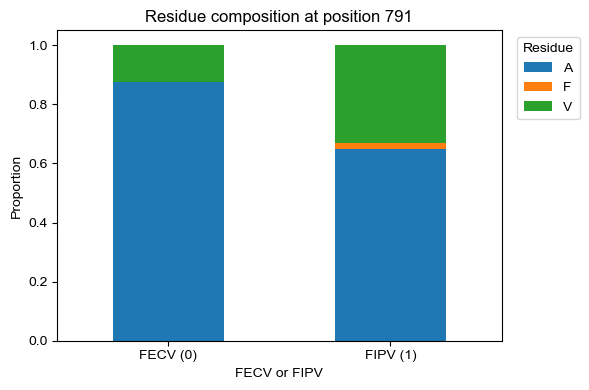

In [92]:
pos = 791  # 1-based position (表示用/ゲノム座標)
offset = 778

df = df_selected.copy()

# 文字列のインデックス指定には、元の 0-based インデックスを使用する
# 791 - 778 = 13 (元のpos)
# 13 - 1 = 12 (0始まりのインデックス)
df["Residue"] = df["Seq"].str[pos - offset - 1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- 以下、グラフ描画コードはそのまま ---
prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}") # タイトルには 791 が出る
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

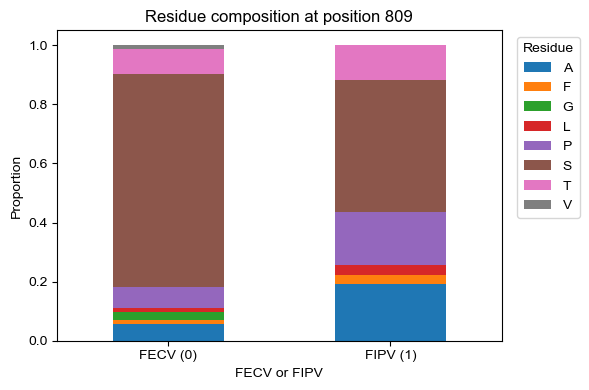

In [91]:
pos = 809  # 1-based position (表示用/ゲノム座標)
offset = 778

df = df_selected.copy()

# 文字列のインデックス指定には、元の 0-based インデックスを使用する
# 809 - 778 = 31 (元のpos)

df["Residue"] = df["Seq"].str[pos - offset - 1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- 以下、グラフ描画コードはそのまま ---
prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}") # タイトルには 791 が出る
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

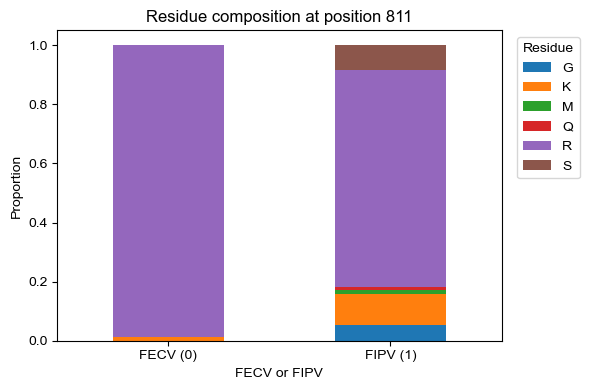

In [90]:
pos = 811  # 1-based position (表示用/ゲノム座標)
offset = 778

df = df_selected.copy()

# 文字列のインデックス指定には、元の 0-based インデックスを使用する
# 811 - 778 = 33 (元のpos)

df["Residue"] = df["Seq"].str[pos - offset - 1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- 以下、グラフ描画コードはそのまま ---
prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}") # タイトルには 791 が出る
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

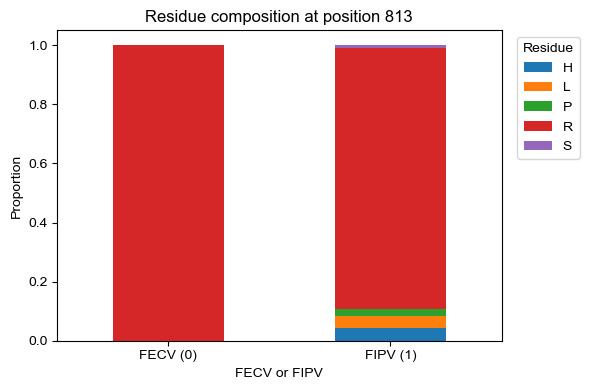

In [89]:
pos = 813  # 1-based position (表示用/ゲノム座標)
offset = 778

df = df_selected.copy()

# 文字列のインデックス指定には、元の 0-based インデックスを使用する
# 813 - 778 = 35 (元のpos)

df["Residue"] = df["Seq"].str[pos - offset - 1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- 以下、グラフ描画コードはそのまま ---
prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}") # タイトルには 791 が出る
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

ゲノム座標: 814
アライメント上のインデックス(0始まり): 35
アライメント上の位置(1始まり): 36


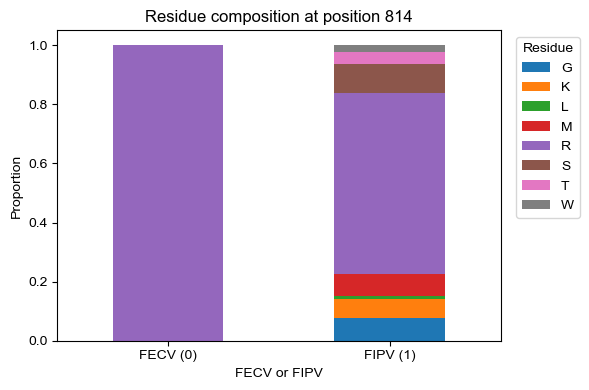

In [88]:
# 表示したいゲノム上の座標
pos = 814  
# 解析で使用したOFFSET（1039）
offset = 779

# --- インデックス計算メモ ---
# アライメント上の 1始まりのインデックス: (pos - offset) + 1
# 0始まりの文字列インデックス: (pos - offset)
seq_idx = pos - offset 
alignment_pos_1based = seq_idx + 1

print(f"ゲノム座標: {pos}")
print(f"アライメント上のインデックス(0始まり): {seq_idx}")
print(f"アライメント上の位置(1始まり): {alignment_pos_1based}")

df = df_selected.copy()
df["Residue"] = df["Seq"].str[seq_idx]

# --- Gap の除外 ---
df_filtered = df[df["Residue"] != "-"]

# 比率の計算
prop = (df_filtered.groupby(["FIP_label", "Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- グラフ描画 ---
prop.plot(kind="bar", stacked=True, figsize=(6, 4))
plt.ylabel("Proportion")
# タイトルにゲノム座標とアライメント上の位置(1始まり)を明示
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0, 1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

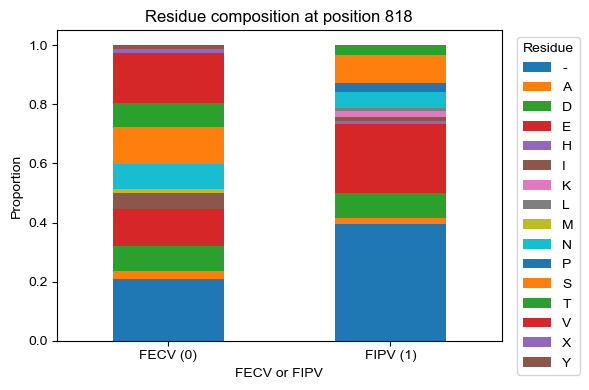

In [87]:
pos = 818  # 1-based position (表示用/ゲノム座標)
offset = 778

df = df_selected.copy()

# 文字列のインデックス指定には、元の 0-based インデックスを使用する
# 818 - 778 =  (元のpos)

df["Residue"] = df["Seq"].str[pos - offset - 1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

# --- 以下、グラフ描画コードはそのまま ---
prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}") # タイトルには 791 が出る
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()